In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb

# 1. Cargar dataset
df = pd.read_csv('../data/raw/telco_churn_raw.csv')

# 2. Diagnóstico inicial
print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas\n")
print(df.info())
print("\nValores nulos detectados:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dimensiones: 7043 filas x 23 columnas

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Pap

In [2]:
# 1. Limpieza de espacios y conversión a numérico
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].astype(str).str.strip(), errors='coerce')

# 2. Imputar nulos (clientes sin historial previo acumulan $0)
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# 3. Creación de variable objetivo binaria para cálculos analíticos
df['Churn_Flag'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4. Homogeneizar etiquetas categóricas
cols_reemplazo = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 
                  'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in cols_reemplazo:
    df[col] = df[col].replace({'No internet service': 'No'})

df['MultipleLines'] = df['MultipleLines'].replace({'No phone service': 'No'})

In [3]:
# 1. Agrupamiento por cohortes de antigüedad (Tenure)
bins = [-1, 12, 24, 48, 72]
labels = ['0-12 meses', '13-24 meses', '25-48 meses', '49-72 meses']
df['Tenure_Cohort'] = pd.cut(df['tenure'], bins=bins, labels=labels)

# 2. Variable agregada: Total de servicios de valor agregado contratados
servicios_adicionales = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport']
df['Total_Security_Services'] = (df[servicios_adicionales] == 'Yes').sum(axis=1)

# 3. Extracción SQL: Impacto financiero de la deserción por tipo de contrato
query_mrr = """
SELECT 
    Contract,
    COUNT(*) AS total_clientes,
    SUM(Churn_Flag) AS clientes_fugados,
    ROUND(AVG(Churn_Flag) * 100, 2) AS churn_rate_pct,
    ROUND(AVG(MonthlyCharges), 2) AS ticket_promedio,
    ROUND(SUM(CASE WHEN Churn_Flag = 1 THEN MonthlyCharges ELSE 0 END), 2) AS mrr_perdido_mensual
FROM df
GROUP BY Contract
ORDER BY churn_rate_pct DESC;
"""
resumen_contratos = duckdb.query(query_mrr).to_df()
display(resumen_contratos)

,Contract,total_clientes,clientes_fugados,churn_rate_pct,ticket_promedio,mrr_perdido_mensual
0,Month-to-month,3875,1655.0,42.71,66.40,120847.10
1,One year,1473,166.0,11.27,65.05,14118.45
2,Two year,1695,48.0,2.83,60.77,4165.30


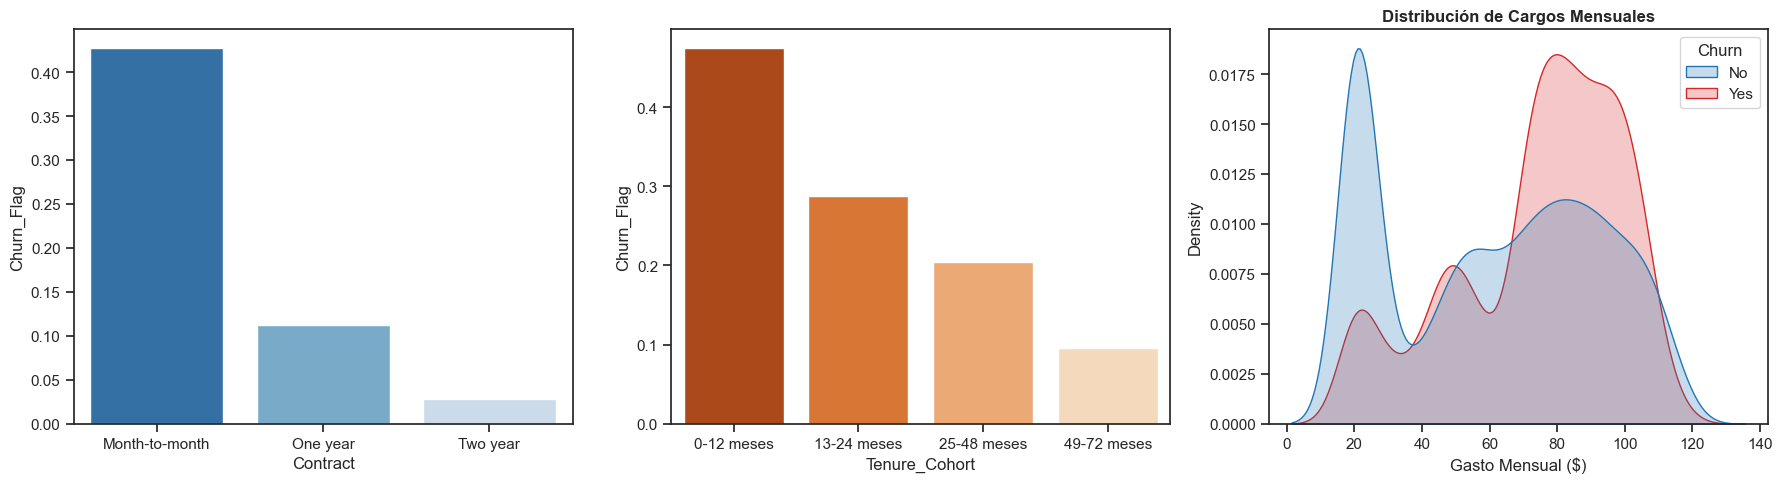

In [6]:
sns.set_theme(style="ticks")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico A: Tasa de Churn por tipo de contrato
contract_order = df.groupby('Contract')['Churn_Flag'].mean().sort_values(ascending=False).index
sns.barplot(
    data=df, x='Contract', y='Churn_Flag', order=contract_order,
    hue='Contract', palette='Blues_r', legend=False, errorbar=None, ax=axes[0]
)

# Gráfico B: Tasa de Churn por Cohorte de Antigüedad
sns.barplot(
    data=df, x='Tenure_Cohort', y='Churn_Flag',
    hue='Tenure_Cohort', palette='Oranges_r', legend=False, errorbar=None, ax=axes[1]
)

# Gráfico C: Distribución de Monthly Charges por Churn
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, ax=axes[2], palette=['#1f77b4', '#d62728'])
axes[2].set_title('Distribución de Cargos Mensuales', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Gasto Mensual ($)')

plt.tight_layout()
plt.show()

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Seleccionar y escalar variables para el clustering
features = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# 2. Entrenar K-Means con k=3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster_ID'] = kmeans.fit_predict(X_scaled)

# 3. Analizar medias por cluster para asignar nombres de negocio
perfil_clusters = df.groupby('Cluster_ID')[features + ['Churn_Flag']].mean()
print(perfil_clusters)

# 4. Mapear etiquetas según promedios calculados
# Identifica qué cluster tiene bajo tenure y alto churn para 'Riesgo Crítico'
cluster_mapping = {
    0: 'Clientes Maduros - Alto Valor',
    1: 'Nuevos Clientes - Riesgo Crítico',
    2: 'Bajo Consumo - Estables'
}
df['Customer_Segment'] = df['Cluster_ID'].map(cluster_mapping)

# 5. Exportar el dataset limpio y enriquecido para Power BI
df.to_csv('../data/processed/telco_churn_enriched.csv', index=False)
print("Archivo 'telco_churn_enriched.csv' exportado exitosamente en data/processed/")

               tenure  MonthlyCharges  TotalCharges  Churn_Flag
Cluster_ID                                                     
0           29.498143       26.572864    809.419916    0.123027
1           58.559545       89.697932   5246.126386    0.153636
2           13.246560       74.950985   1030.569041    0.470807
Archivo 'telco_churn_enriched.csv' exportado exitosamente en data/processed/


## Conclusiones y hallazgos

### 1. El churn representa un riesgo financiero relevante

El dataset contiene **7.043 clientes** y presenta un churn global de **26,54%**. Las bajas representan aproximadamente **$139.130,85 de cargos mensuales** que dejan de facturarse, por lo que la retención debe enfocarse en reducir las bajas de los perfiles con mayor exposición económica.

### 2. El contrato mensual concentra el mayor riesgo

Los clientes con contrato **Month-to-month** tienen una tasa de churn de **42,71%**, frente a **11,27%** en contratos de un año y **2,83%** en contratos de dos años. Además, este grupo concentra aproximadamente **$120.847,10 de MRR perdido**. Una estrategia prioritaria es incentivar la migración a contratos de mayor permanencia mediante beneficios de renovación, paquetes de servicios y ofertas de valor claramente comunicadas.

### 3. El método de pago es una señal de fricción

**Electronic check** registra el mayor churn entre los métodos de pago, con **45,29%**, muy por encima de las tarjetas automáticas (**15,24%**) y las transferencias automáticas (**16,71%**). Este patrón justifica revisar la experiencia de cobro, los fallos de autorización y los recordatorios de pago para este grupo.

### 4. La ventana crítica está en el primer año

La cohorte de **0-12 meses** alcanza un churn de **47,44%** y concentra el **55,48% de todas las bajas**. El churn desciende a **28,71%** entre 13-24 meses, **20,39%** entre 25-48 meses y **9,51%** entre 49-72 meses. El onboarding, el seguimiento de los primeros meses y las campañas de prevención temprana son, por tanto, los puntos de intervención con mayor potencial.

### 5. La segmentación K-Means revela un perfil prioritario

El clustering se construyó con `tenure`, `MonthlyCharges` y `TotalCharges`, escaladas previamente, usando **K-Means con 3 clusters**. El perfil con mayor riesgo observado presenta:

- **13,25 meses** de antigüedad promedio.
- **$74,95** de cargo mensual promedio.
- **47,08%** de churn.

Los otros perfiles presentan churn de **12,30%** y **15,36%**, por lo que no deben recibir el mismo tratamiento. La segmentación puede utilizarse para personalizar la retención, pero conviene recalibrar los nombres de negocio de los clusters a partir de sus medias reales antes de publicar el dashboard.

### Recomendación final

Priorizar campañas para clientes nuevos o de baja antigüedad con contrato mensual y pago mediante `Electronic check`; medir conversión a contratos de mayor permanencia, reducción de fallos de cobro y churn a 30, 60 y 90 días. Estos indicadores conectan los hallazgos exploratorios con acciones concretas de retención.